# Fine-Tuning with Auxiliary Losses
Requires `finetune_setup.ipynb` to have been run first.

This notebook tests a fine-tuning variant where the unfrozen transformer blocks also optimize auxiliary reconstruction losses (similar to the original BrainOmni pretraining objective) in addition to the AD classification loss. The hypothesis is that auxiliary losses regularize the blocks so they do not overfit the small AD dataset.

In [ ]:
import os, sys, json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
from tqdm import tqdm

sys.path.insert(0, '/Users/faenegoro/Documents/Neuroimaging/BrainOmni')
from brainomni.model import BrainOmni

device = torch.device('mps') if torch.backends.mps.is_available() else torch.device('cpu')
print('Device:', device)

In [ ]:
CKPT_PATH = '/Users/faenegoro/Documents/Neuroimaging/BrainOmni/ckpt_collection/tiny'
SAVE_DIR  = '../data/preprocessed'
OUT_DIR   = '../results/figures'
os.makedirs(OUT_DIR, exist_ok=True)

with open(os.path.join(CKPT_PATH, 'model_cfg.json')) as f:
    model_config = json.load(f)
base_checkpoint = torch.load(
    os.path.join(CKPT_PATH, 'BrainOmni.pt'), map_location='cpu', weights_only=True
)

proj_out1 = np.load(os.path.join(SAVE_DIR, 'proj_out1.npy'))  # (N, 16, NT, 256)
proj_out2 = np.load(os.path.join(SAVE_DIR, 'proj_out2.npy'))
labels    = np.load(os.path.join(SAVE_DIR, 'labels.npy'))
split     = np.load(os.path.join(SAVE_DIR, 'split.npz'))
train_idx, val_idx, test_idx = split['train_idx'], split['val_idx'], split['test_idx']

print(f'Loaded {len(proj_out1)} subjects | proj_out shape: {proj_out1.shape}')
print(f'Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)}')

Loaded 148 subjects | proj_out shape: (148, 16, 160, 256)
Train: 118 | Val: 15 | Test: 15


## Design

The auxiliary loss is cosine similarity between the two segment embeddings. During pretraining, BrainOmni learns that two segments from the same subject should produce similar representations. We keep this as a regularizer during fine-tuning:

```
total_loss = cls_loss + lambda_aux * aux_loss
aux_loss   = 1 - cosine_similarity(embed1, embed2)
```

We test three values of `lambda_aux`: 0.1, 0.5, 1.0.

In [ ]:
class FullMEGDataset(Dataset):
    """Returns cached tokenizer outputs (after frozen blocks), one subject at a time."""
    def __init__(self, indices, cached1, cached2, labels):
        self.indices = indices
        self.cached1 = cached1
        self.cached2 = cached2
        self.labels  = labels
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        idx = self.indices[i]
        return self.cached1[idx], self.cached2[idx], torch.tensor(self.labels[idx], dtype=torch.long)

class AuxFinetuneClassifier(nn.Module):
    def __init__(self, encoder_blocks, hidden_dim=256):
        super().__init__()
        self.blocks = encoder_blocks
        self.head = nn.Sequential(
            nn.Linear(hidden_dim * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 2)
        )
    def forward(self, x1, x2):
        x1, x2 = x1.to(device), x2.to(device)
        for block in self.blocks:
            x1 = block(x1)
            x2 = block(x2)
        x1_pool = F.normalize(x1, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        x2_pool = F.normalize(x2, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        avg = ((x1_pool + x2_pool) / 2).flatten(1)
        logits = self.head(avg)
        return logits, x1_pool.flatten(1), x2_pool.flatten(1)

def cosine_similarity_loss(e1, e2):
    """Mean (1 - cosine_sim) over the batch: 0 when identical, 2 when opposite."""
    sim = F.cosine_similarity(e1, e2, dim=-1)
    return (1 - sim).mean()

def run_aux_finetune(n_frozen=8, lambda_aux=0.5, max_epochs=200, patience=20):
    label = f'N_frozen={n_frozen} | lambda_aux={lambda_aux}'
    print(f'\n=== {label} ===')

    model = BrainOmni(**model_config)
    model.load_state_dict(base_checkpoint, strict=False)
    for param in model.parameters():
        param.requires_grad = False
    model = model.to(device).eval()

    # Cache output of frozen blocks — proj_out1/proj_out2 already tokenized
    cached1, cached2 = [], []
    with torch.no_grad():
        for i in tqdm(range(len(proj_out1)), desc='Caching', leave=False):
            x1 = torch.tensor(proj_out1[i]).unsqueeze(0).to(device)
            x2 = torch.tensor(proj_out2[i]).unsqueeze(0).to(device)
            for block in list(model.blocks)[:n_frozen]:
                x1 = block(x1)
                x2 = block(x2)
            cached1.append(x1.squeeze(0).cpu())
            cached2.append(x2.squeeze(0).cpu())

    train_loader = DataLoader(FullMEGDataset(train_idx, cached1, cached2, labels), batch_size=8, shuffle=True)
    val_loader   = DataLoader(FullMEGDataset(val_idx,   cached1, cached2, labels), batch_size=8)
    test_loader  = DataLoader(FullMEGDataset(test_idx,  cached1, cached2, labels), batch_size=8)

    unfrozen = nn.ModuleList(list(model.blocks)[n_frozen:-1])
    for param in unfrozen.parameters():
        param.requires_grad = True
    ft_model  = AuxFinetuneClassifier(unfrozen, hidden_dim=256).to(device)
    optimizer = torch.optim.Adam(ft_model.parameters(), lr=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=0.5, patience=7, min_lr=1e-6
    )
    criterion = nn.CrossEntropyLoss()

    best_val, patience_count, best_weights = 0, 0, None
    train_accs, val_accs, train_losses, val_losses = [], [], [], []

    for epoch in range(max_epochs):
        ft_model.train()
        preds, trues, epoch_loss = [], [], 0.0
        for x1, x2, y in train_loader:
            optimizer.zero_grad()
            logits, e1, e2 = ft_model(x1, x2)
            cls_loss = criterion(logits, y.to(device))
            aux_loss = cosine_similarity_loss(e1, e2)
            loss     = cls_loss + lambda_aux * aux_loss
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            preds.extend(logits.argmax(1).cpu().numpy())
            trues.extend(y.numpy())
        train_acc  = accuracy_score(trues, preds)
        train_loss = epoch_loss / len(train_loader)

        ft_model.eval()
        preds, trues, val_loss_sum = [], [], 0.0
        with torch.no_grad():
            for x1, x2, y in val_loader:
                logits, e1, e2 = ft_model(x1, x2)
                val_loss_sum += (criterion(logits, y.to(device)) + lambda_aux * cosine_similarity_loss(e1, e2)).item()
                preds.extend(logits.argmax(1).cpu().numpy())
                trues.extend(y.numpy())
        val_acc  = accuracy_score(trues, preds)
        val_loss = val_loss_sum / len(val_loader)

        train_accs.append(train_acc)
        val_accs.append(val_acc)
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        current_lr = optimizer.param_groups[0]['lr']
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f'  Epoch {epoch+1:03d} | Train: {train_acc:.3f} (loss {train_loss:.4f}) | Val: {val_acc:.3f} (loss {val_loss:.4f}) | LR: {current_lr:.2e}')

        scheduler.step(val_acc)

        if val_acc > best_val:
            best_val = val_acc
            best_weights = {k: v.clone() for k, v in ft_model.state_dict().items()}
            patience_count = 0
        else:
            patience_count += 1
            if patience_count >= patience:
                print(f'  Early stopping at epoch {epoch+1}')
                break

    ft_model.load_state_dict(best_weights)
    ft_model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for x1, x2, y in test_loader:
            logits, _, _ = ft_model(x1, x2)
            preds.extend(logits.argmax(1).cpu().numpy())
            trues.extend(y.numpy())
    test_acc = accuracy_score(trues, preds)
    print(f'  Best val: {best_val:.3f} | Test acc: {test_acc:.3f}')
    print(classification_report(trues, preds, target_names=['Control', 'AD']))

    return {
        'lambda_aux': lambda_aux, 'n_frozen': n_frozen,
        'best_val': best_val, 'test_acc': test_acc,
        'train_accs': train_accs, 'val_accs': val_accs,
        'train_losses': train_losses, 'val_losses': val_losses
    }

print('Helpers ready.')

Helpers ready.


## Run Experiments
Testing 3 values of `lambda_aux` with the last 3 blocks unfrozen (n_frozen=8).

In [ ]:
aux_results = {}
for lam in [0.1, 0.5, 1.0]:
    aux_results[lam] = run_aux_finetune(n_frozen=8, lambda_aux=lam)


=== N_frozen=8 | lambda_aux=0.1 ===


  Epoch 001 | Train: 0.475 (loss 0.6961) | Val: 0.533 (loss 0.6898) | LR: 1.00e-04
  Epoch 010 | Train: 0.881 (loss 0.3235) | Val: 0.600 (loss 0.7215) | LR: 1.00e-04
  Epoch 020 | Train: 0.915 (loss 0.2841) | Val: 0.600 (loss 0.8747) | LR: 5.00e-05
  Early stopping at epoch 27
  Best val: 0.733 | Test acc: 0.800
              precision    recall  f1-score   support

     Control       0.70      1.00      0.82         7
          AD       1.00      0.62      0.77         8

    accuracy                           0.80        15
   macro avg       0.85      0.81      0.80        15
weighted avg       0.86      0.80      0.79        15


=== N_frozen=8 | lambda_aux=0.5 ===


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  Epoch 001 | Train: 0.492 (loss 0.6980) | Val: 0.467 (loss 0.6936) | LR: 1.00e-04
  Epoch 010 | Train: 0.839 (loss 0.4085) | Val: 0.667 (loss 0.6157) | LR: 1.00e-04
  Epoch 020 | Train: 0.873 (loss 0.3456) | Val: 0.667 (loss 0.7449) | LR: 5.00e-05
  Early stopping at epoch 26
  Best val: 0.667 | Test acc: 0.667
              precision    recall  f1-score   support

     Control       0.58      1.00      0.74         7
          AD       1.00      0.38      0.55         8

    accuracy                           0.67        15
   macro avg       0.79      0.69      0.64        15
weighted avg       0.81      0.67      0.63        15


=== N_frozen=8 | lambda_aux=1.0 ===


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  Epoch 001 | Train: 0.525 (loss 0.6964) | Val: 0.600 (loss 0.6916) | LR: 1.00e-04
  Epoch 010 | Train: 0.839 (loss 0.4225) | Val: 0.733 (loss 0.7260) | LR: 1.00e-04
  Epoch 020 | Train: 0.898 (loss 0.3313) | Val: 0.600 (loss 0.6721) | LR: 5.00e-05
  Early stopping at epoch 25
  Best val: 0.733 | Test acc: 0.867
              precision    recall  f1-score   support

     Control       0.78      1.00      0.88         7
          AD       1.00      0.75      0.86         8

    accuracy                           0.87        15
   macro avg       0.89      0.88      0.87        15
weighted avg       0.90      0.87      0.87        15



## Summary Table

In [ ]:
print('=== Auxiliary Loss Experiment Results ===')
print(f'{"lambda_aux":<12} {"Best Val":<12} {"Test Acc"}')
print('-' * 36)
for lam, res in aux_results.items():
    print(f'{lam:<12} {res["best_val"]:<12.3f} {res["test_acc"]:.3f}')

print('\n--- Baseline (no aux loss, n_frozen=8, from finetune_blocks.ipynb) ---')
print('Load ft_results.pt and check n_frozen=8 test_acc for comparison.')

=== Auxiliary Loss Experiment Results ===
lambda_aux   Best Val     Test Acc
------------------------------------
0.1          0.733        0.800
0.5          0.667        0.667
1.0          0.733        0.867

--- Baseline (no aux loss, n_frozen=8, from finetune_blocks.ipynb) ---
Load ft_results.pt and check n_frozen=8 test_acc for comparison.


## Training Curves

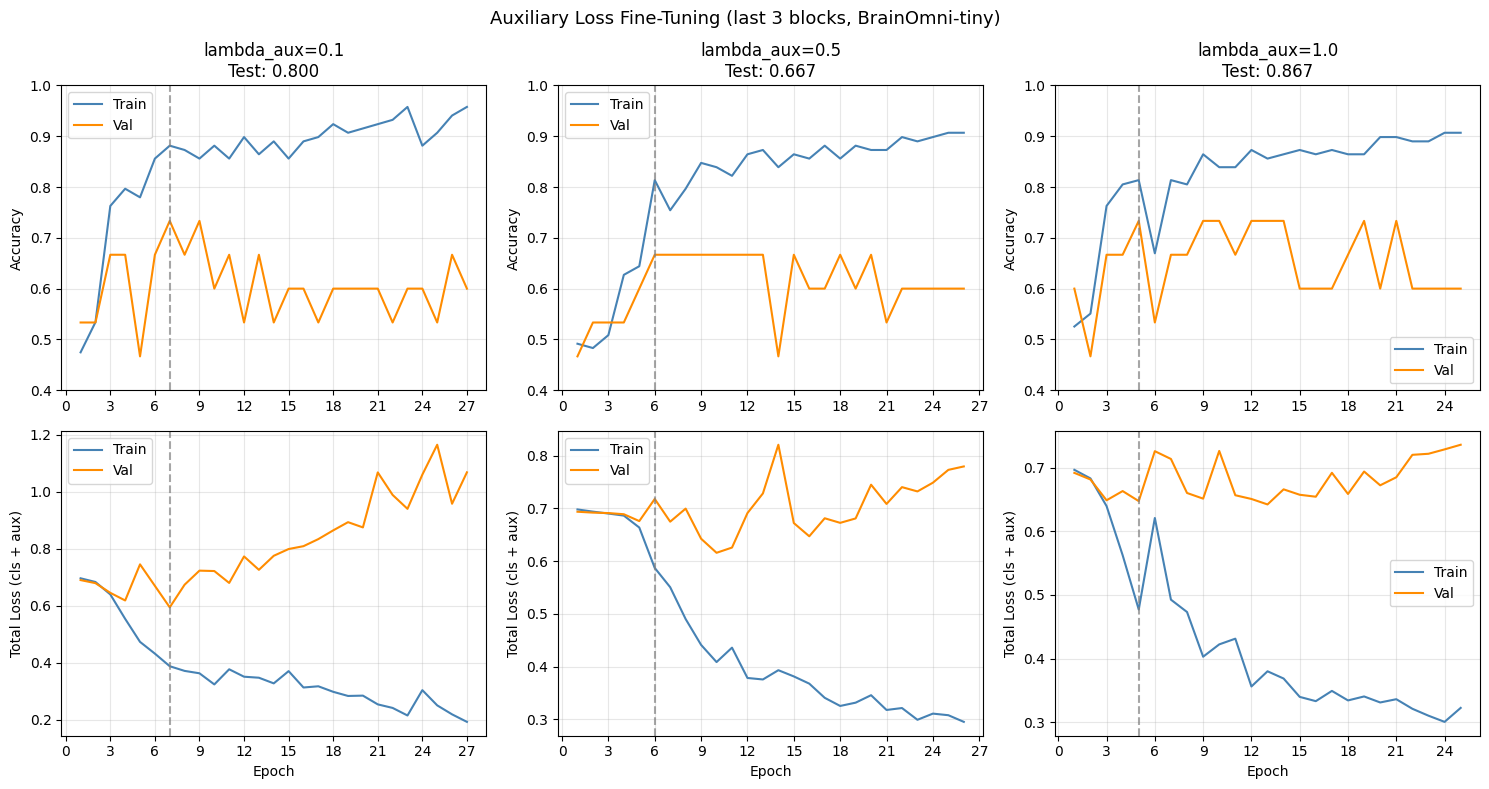

Saved finetune_aux_curves.png


In [ ]:
lambdas = list(aux_results.keys())
fig, axes = plt.subplots(2, len(lambdas), figsize=(5 * len(lambdas), 8))

for col, lam in enumerate(lambdas):
    res    = aux_results[lam]
    epochs = range(1, len(res['train_accs']) + 1)
    best_ep = int(np.argmax(res['val_accs'])) + 1

    ax = axes[0, col]
    ax.plot(epochs, res['train_accs'], '-', label='Train', color='steelblue')
    ax.plot(epochs, res['val_accs'],   '-', label='Val',   color='darkorange')
    ax.axvline(best_ep, color='gray', linestyle='--', alpha=0.7)
    ax.set_title(f'lambda_aux={lam}\nTest: {res["test_acc"]:.3f}')
    ax.set_ylabel('Accuracy')
    ax.set_ylim(0.4, 1.0)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.legend()
    ax.grid(alpha=0.3)

    ax = axes[1, col]
    ax.plot(epochs, res['train_losses'], '-', label='Train', color='steelblue')
    ax.plot(epochs, res['val_losses'],   '-', label='Val',   color='darkorange')
    ax.axvline(best_ep, color='gray', linestyle='--', alpha=0.7)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Total Loss (cls + aux)')
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle('Auxiliary Loss Fine-Tuning (last 3 blocks, BrainOmni-tiny)', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'finetune_aux_curves.png'), dpi=150)
plt.show()
print('Saved finetune_aux_curves.png')